In [4]:
# %% [markdown]
"""
# Predictive Maintenance for Festo Conveyor System

**Objective:**  
- Build predictive models that allow for early detection of mechanical faults and forecast the pneumatic pressure.
  
**System Overview:**  
- The system monitors a conveyor with a gripper passing points A, C, and B.
- There are four sensor configurations corresponding to:
    - AC: Sensors along route A → C  
    - CA: Sensors along route C → A  
    - CB: Sensors along route C → B  
    - BC: Sensors along route B → C  
- External conditions include system pressure and potential faults.
  
**Output:**  
The system will output three values:
  - `mech_1_prediction`: Fault prediction (0/1) for sensors A and C.
  - `mech_2_prediction`: Fault prediction (0/1) for sensors C and B.
  - `pressure_prediction`: Predicted pressure (a continuous value).
"""
# %% 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, classification_report, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

import warnings
warnings.filterwarnings('ignore')

# %% [markdown]
"""
## 1. Data Loading and Preprocessing

We load the four CSV files.  
Each file is assumed to have no header or the appropriate header is provided.  
If your CSV files do not have headers, we will assign them as:  
    ['Time series', 'Pressure', 'Fault']

We then assign a sensor configuration label to each file.
"""
# %% 
# Adjust the file paths as needed.
ac_df = pd.read_csv('C:/Users/Алишер/Desktop/NazarbayevUniversity/DatasetPdM/Class_regres_dataset/AC_Down_to_Sort - Sheet1.csv', header=0)
ca_df = pd.read_csv('C:/Users/Алишер/Desktop/NazarbayevUniversity/DatasetPdM/Class_regres_dataset/CA_Sort_to_Down - Sheet1.csv', header=0)
cb_df = pd.read_csv('C:/Users/Алишер/Desktop/NazarbayevUniversity/DatasetPdM/Class_regres_dataset/CB_Sort_to_Upstream - Sheet1.csv', header=0)
bc_df = pd.read_csv('C:/Users/Алишер/Desktop/NazarbayevUniversity/DatasetPdM/Class_regres_dataset/BC_Upstream_to_Sort - Sheet1.csv', header=0)

# Assume each file has 3 columns; if a file has extra columns, select only the first 3.
ac_df = ac_df.iloc[:, :3]
ca_df = ca_df.iloc[:, :3]
cb_df = cb_df.iloc[:, :3]
bc_df = bc_df.iloc[:, :3]

# Assign column names
col_names = ['Time series', 'Pressure', 'Fault']
ac_df.columns = col_names
ca_df.columns = col_names
cb_df.columns = col_names
bc_df.columns = col_names

# Add a sensor configuration column
ac_df['sensor_config'] = 'AC'
ca_df['sensor_config'] = 'CA'
cb_df['sensor_config'] = 'CB'
bc_df['sensor_config'] = 'BC'

In [5]:
# %% [markdown]
"""
### Prepare Datasets for Each Task

For **mech_1** (fault detection between sensors A and C), combine AC and CA files.  
For **mech_2** (fault detection between sensors C and B), combine CB and BC files.  
For pressure regression, combine all files and use the sensor configuration as an additional feature.
"""
# %% 
# Dataset for mech_1 classification:
df_mech1 = pd.concat([ac_df, ca_df], axis=0).copy()
df_mech1['mech_1'] = df_mech1['Fault']  # Use Fault column for mech_1
df_mech1 = df_mech1.drop(columns=['Fault'])

# Dataset for mech_2 classification:
df_mech2 = pd.concat([cb_df, bc_df], axis=0).copy()
df_mech2['mech_2'] = df_mech2['Fault']  # Use Fault column for mech_2
df_mech2 = df_mech2.drop(columns=['Fault'])

# Dataset for pressure regression:
df_pressure = pd.concat([ac_df, ca_df, cb_df, bc_df], axis=0).copy()
# We keep only the columns needed
df_pressure = df_pressure[['Time series', 'Pressure', 'sensor_config']]
# One-hot encode the sensor configuration so that the model can use it as an input feature
df_pressure = pd.get_dummies(df_pressure, columns=['sensor_config'])

In [6]:
# %% [markdown]
"""
## 2. Modeling Preparation

We now prepare features (X) and targets (y) for the three tasks.
We then split each dataset into training, validation, and test sets.
"""
# %% 
# For mech_1 classification:
X_mech1 = df_mech1[['Time series']]  # You can add more features if available
y_mech1 = df_mech1['mech_1']
X_mech1_train, X_mech1_temp, y_mech1_train, y_mech1_temp = train_test_split(
    X_mech1, y_mech1, test_size=0.3, random_state=42, stratify=y_mech1)
X_mech1_val, X_mech1_test, y_mech1_val, y_mech1_test = train_test_split(
    X_mech1_temp, y_mech1_temp, test_size=0.5, random_state=42)

# For mech_2 classification:
X_mech2 = df_mech2[['Time series']]
y_mech2 = df_mech2['mech_2']
X_mech2_train, X_mech2_temp, y_mech2_train, y_mech2_temp = train_test_split(
    X_mech2, y_mech2, test_size=0.3, random_state=42, stratify=y_mech2)
X_mech2_val, X_mech2_test, y_mech2_val, y_mech2_test = train_test_split(
    X_mech2_temp, y_mech2_temp, test_size=0.5, random_state=42)

# For pressure regression:
X_pressure = df_pressure.drop(columns=['Pressure'])
y_pressure = df_pressure['Pressure']
X_pressure_train, X_pressure_temp, y_pressure_train, y_pressure_temp = train_test_split(
    X_pressure, y_pressure, test_size=0.3, random_state=42)
X_pressure_val, X_pressure_test, y_pressure_val, y_pressure_test = train_test_split(
    X_pressure_temp, y_pressure_temp, test_size=0.5, random_state=42)

In [7]:
# %% [markdown]
"""
### Preprocessing Pipelines

We create pipelines for classification (using the "Time series" as feature) and for regression (which uses time and sensor configuration).
"""
# %% 
clf_preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

reg_preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Transform the features for classification tasks
X_mech1_train_scaled = clf_preprocessor.fit_transform(X_mech1_train)
X_mech1_val_scaled = clf_preprocessor.transform(X_mech1_val)
X_mech1_test_scaled = clf_preprocessor.transform(X_mech1_test)

X_mech2_train_scaled = clf_preprocessor.fit_transform(X_mech2_train)
X_mech2_val_scaled = clf_preprocessor.transform(X_mech2_val)
X_mech2_test_scaled = clf_preprocessor.transform(X_mech2_test)

# Transform the features for regression
X_pressure_train_scaled = reg_preprocessor.fit_transform(X_pressure_train)
X_pressure_val_scaled = reg_preprocessor.transform(X_pressure_val)
X_pressure_test_scaled = reg_preprocessor.transform(X_pressure_test)


In [8]:
# %% [markdown]
"""
## 3. Model Training and Evaluation

We now train the models:
- **Random Forest Classifier** for mech_1.
- **Random Forest Classifier** for mech_2.
- **Random Forest Regressor** for pressure.
"""
# %% 
# Train and evaluate classifier for mech_1:
mech1_clf = RandomForestClassifier(n_estimators=100, random_state=42)
mech1_clf.fit(X_mech1_train_scaled, y_mech1_train)

y_mech1_val_pred = mech1_clf.predict(X_mech1_val_scaled)
print("Validation results for mech_1 classifier:")
print("Accuracy:", accuracy_score(y_mech1_val, y_mech1_val_pred))
print(classification_report(y_mech1_val, y_mech1_val_pred))

# Train and evaluate classifier for mech_2:
mech2_clf = RandomForestClassifier(n_estimators=100, random_state=42)
mech2_clf.fit(X_mech2_train_scaled, y_mech2_train)

y_mech2_val_pred = mech2_clf.predict(X_mech2_val_scaled)
print("Validation results for mech_2 classifier:")
print("Accuracy:", accuracy_score(y_mech2_val, y_mech2_val_pred))
print(classification_report(y_mech2_val, y_mech2_val_pred))

# Train and evaluate regressor for pressure:
pressure_reg = RandomForestRegressor(n_estimators=100, random_state=42)
pressure_reg.fit(X_pressure_train_scaled, y_pressure_train)

y_pressure_val_pred = pressure_reg.predict(X_pressure_val_scaled)
mse_val = mean_squared_error(y_pressure_val, y_pressure_val_pred)
r2_val = r2_score(y_pressure_val, y_pressure_val_pred)
print("Validation results for pressure regression:")
print(f"Mean Squared Error: {mse_val:.2f}")
print(f"R-squared: {r2_val:.2f}")

Validation results for mech_1 classifier:
Accuracy: 0.8267716535433071
              precision    recall  f1-score   support

           0       0.87      0.87      0.87        87
           1       0.72      0.72      0.72        40

    accuracy                           0.83       127
   macro avg       0.80      0.80      0.80       127
weighted avg       0.83      0.83      0.83       127

Validation results for mech_2 classifier:
Accuracy: 0.8110236220472441
              precision    recall  f1-score   support

           0       0.88      0.81      0.85        81
           1       0.71      0.80      0.76        46

    accuracy                           0.81       127
   macro avg       0.80      0.81      0.80       127
weighted avg       0.82      0.81      0.81       127

Validation results for pressure regression:
Mean Squared Error: 0.22
R-squared: 0.74


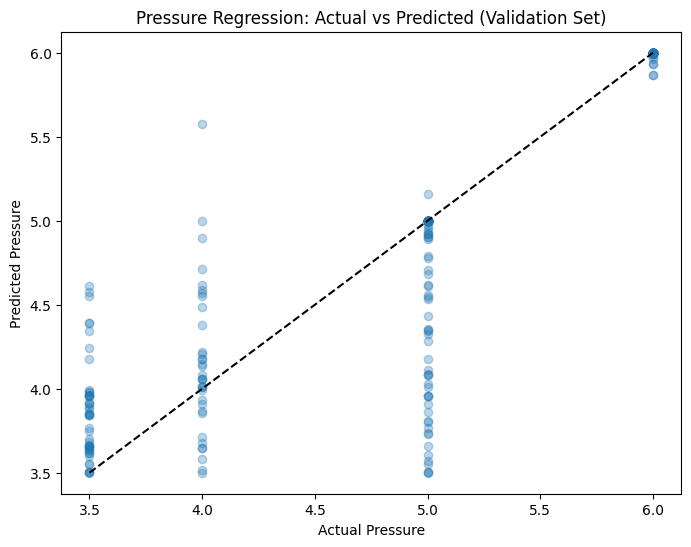

In [9]:
# Optionally, plot Actual vs Predicted Pressure on the validation set:
plt.figure(figsize=(8,6))
plt.scatter(y_pressure_val, y_pressure_val_pred, alpha=0.3)
plt.plot([y_pressure_val.min(), y_pressure_val.max()],
         [y_pressure_val.min(), y_pressure_val.max()], 'k--')
plt.xlabel('Actual Pressure')
plt.ylabel('Predicted Pressure')
plt.title('Pressure Regression: Actual vs Predicted (Validation Set)')
plt.show()


In [10]:
# %% [markdown]
"""
## 4. Deployment Function

This function accepts new input data (a time series value and a sensor configuration) and returns:
- A prediction for mech_1 (if the configuration is "AC" or "CA"),
- A prediction for mech_2 (if the configuration is "CB" or "BC"),
- A predicted pressure value.
"""
# %% 
def predict_system_status(time_value, sensor_config):
    """
    Parameters:
      - time_value: A numeric value (time in milliseconds).
      - sensor_config: A string indicating sensor configuration ('AC', 'CA', 'CB', 'BC').
    
    Returns:
      Dictionary with keys:
         'mech_1_prediction', 'mech_2_prediction', 'pressure_prediction'
    """
    # For classification predictions, we use only "Time series"
    input_clf = pd.DataFrame({'Time series': [time_value]})
    input_clf_scaled = clf_preprocessor.transform(input_clf)
    
    # For pressure regression, we need the sensor configuration.
    # Create a DataFrame that includes time and one-hot encoded sensor configuration.
    input_reg = pd.DataFrame({'Time series': [time_value]})
    # For the sensor configuration, create columns named like sensor_config_AC, sensor_config_BC, etc.
    for config in ['AC', 'BC', 'CA', 'CB']:
        input_reg[f'sensor_config_{config}'] = [1 if sensor_config.upper() == config else 0]
    # Preprocess the regression input
    input_reg_scaled = reg_preprocessor.transform(input_reg)
    
    predictions = {}
    
    # For mech_1, if the sensor configuration is AC or CA, predict using mech1_clf
    if sensor_config.upper() in ['AC', 'CA']:
        pred_mech1 = mech1_clf.predict(input_clf_scaled)[0]
        predictions['mech_1_prediction'] = int(pred_mech1)
    else:
        predictions['mech_1_prediction'] = None
    
    # For mech_2, if the sensor configuration is CB or BC, predict using mech2_clf
    if sensor_config.upper() in ['CB', 'BC']:
        pred_mech2 = mech2_clf.predict(input_clf_scaled)[0]
        predictions['mech_2_prediction'] = int(pred_mech2)
    else:
        predictions['mech_2_prediction'] = None
    
    # Pressure prediction is always available
    pred_pressure = pressure_reg.predict(input_reg_scaled)[0]
    predictions['pressure_prediction'] = float(pred_pressure)
    
    return predictions

In [15]:
# %% [markdown]
"""
## 5. Testing the Deployment Function

You can now test the deployment function with different input values.
"""
# %%
# Example tests:
for config in ['AC']:
    pred = predict_system_status(3800, config)
    print(f"Input time_value = 4020, sensor_config = {config}:")
    print(pred)
    print()
for config in ['CB']:
    pred = predict_system_status(4020, config)
    print(f"Input time_value = 4020, sensor_config = {config}:")
    print(pred)
    print()

Input time_value = 4020, sensor_config = AC:
{'mech_1_prediction': 1, 'mech_2_prediction': None, 'pressure_prediction': 4.505}

Input time_value = 4020, sensor_config = CB:
{'mech_1_prediction': None, 'mech_2_prediction': 0, 'pressure_prediction': 3.6975000000000007}

